In [ ]:

import fitness.mobai_utils 

from fitness.mobai_utils import pheno_to_dict, create_final_hierarchy, calculate_AUC_hierarchy
import pandas as pd
import json
import pandas as pd
from tqdm import tqdm
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import MinMaxScaler
import stumpy

In [1]:
df_test = pd.read_csv("../datasets/Mobai/test_set.csv")
df_train = pd.read_csv("../datasets/Mobai/train_set.csv")
filters = pd.read_csv("../datasets/Mobai/not_empty_combinations.csv")
filters = filters.drop(columns="Number of examples (rows)", axis=1)
df_test = df_test[1:].copy()

NameError: name 'pd' is not defined

In [ ]:
available_categories = json.load(open("../datasets/Mobai/available_categories.json"))

In [ ]:
filters

,Call Type,Event Type,Subscriber Type,Traffic Type,Service Type,Partner Description
0,SMS,ORIGINATED,Postpaid,OFF-NET,NOT-ROAMING,P_0001
1,SMS,ORIGINATED,Postpaid,INT,NOT-ROAMING,P_0001
2,SMS,ORIGINATED,Postpaid,ON-NET,NOT-ROAMING,P_0001
3,SMS,ORIGINATED,Roamer In,OFF-NET,NOT-ROAMING,P_0043
4,SMS,ORIGINATED,Roamer In,OFF-NET,NOT-ROAMING,P_0044
...,...,...,...,...,...,...
1550,VOICE,ROAMING OUT,Prepaid,INT,ROAMING,P_0001
1551,VOICE,ROAMING OUT,Prepaid,ON-NET,ROAMING,P_0001
1552,VOICE,ROAMING OUT,Other,OFF-NET,ROAMING,P_0001
1553,VOICE,ROAMING OUT,Other,INT,ROAMING,P_0001


In [ ]:
def build_hierarchy(filters):
    """
    Builds a hierarchical list of dictionaries from a DataFrame.

    Args:
        filters (pd.DataFrame): The input DataFrame.

    Returns:
        list: A list of dictionaries, where each dictionary represents a row in the DataFrame.
    """
    hierarchy = []
    for ir, r in enumerate(filters.iterrows()):
        leaf_dict = {var: filters.loc[ir, var] for var in filters.columns}
        hierarchy.append(leaf_dict)
    return hierarchy

def transform_category_to_list(data, selected_category):
    """
    Transforms a selected category into a list of dictionaries.

    Args:
        data (dict): The input data containing all categories.
        selected_category (str): The name of the category to transform.

    Returns:
        list: A list of dictionaries in the format [{category: value}, ...].
    """
    if selected_category in data:
        return [{selected_category: value} for value in data[selected_category]]
    else:
        return []  # Return an empty list if the category doesn't exist

## 1.1 Generated Hierarchy

In [ ]:
hierarchy = """
  B0
    C0
      A0-END
      A1
        C0
          C0-END
          C1-END
          C2
            E0-END
            E1-END
          C3-END
          C4
            E0-END
            E1-END
        C1-END
        C2
          D0-END
          D1-END
          D2-END
        C3
          E0
            D0-END
            D1-END
            D2-END
          E1-END
        C4
          A0-END
          A1
            C0-END
            C1-END
            C2
              E0-END
              E1-END
            C3-END
            C4-END
    C1-END
    C2-END
    C3
      A0
        E0
          E0
            E0-END
            E1
              D0-END
              D1-END
              D2-END
          E1-END
        E1
          D0-END
          D1-END
          D2
            A0-END
            A1
              A0-END
              A1-END
      A1
        A0
          D0-END
          D1-END
          D2
            A0-END
            A1-END
        A1-END
    C4-END
  B1
    D0
      D0-END
      D1-END
      D2
        A0-END
        A1-END
    D1
      C0-END
      C1-END
      C2
        E0-END
        E1-END
      C3-END
      C4
        D0-END
        D1
          A0-END
          A1-END
        D2-END
    D2
      A0
        E0-END
        E1
          A0-END
          A1-END
      A1
        C0-END
        C1-END
        C2
          E0-END
          E1-END
        C3-END
        C4
          D0
            D0-END
            D1-END
            D2
              D0-END
              D1-END
              D2
                A0-END
                A1-END
          D1
            A0-END
            A1
              D0-END
              D1
                D0-END
                D1-END
                D2
                  A0-END
                  A1
                    A0-END
                    A1-END
              D2
                A0
                  D0-END
                  D1-END
                  D2
                    A0-END
                    A1-END
                A1-END
          D2-END
  B2
    D0
      D0-END
      D1-END
      D2
        A0-END
        A1-END
    D1
      C0-END
      C1-END
      C2
        E0-END
        E1-END
      C3-END
      C4
        D0-END
        D1
          E0-END
          E1-END
        D2-END
    D2
      A0
        E0-END
        E1
          A0-END
          A1-END
      A1
        C0-END
        C1-END
        C2
          E0-END
          E1-END
        C3-END
        C4
          D0
            D0-END
            D1-END
            D2
              D0-END
              D1-END
              D2
                A0-END
                A1-END
          D1
            A0-END
            A1
              D0
                E0
                  A0-END
                  A1-END
                E1-END
              D1-END
              D2
                A0
                  A0
                    C0-END
                    C1-END
                    C2
                      E0-END
                      E1-END
                    C3-END
                    C4-END
                  A1
                    A0-END
                    A1-END
                A1-END
          D2-END
  B3
    A0
      D0-END
      D1
        C0-END
        C1
          D0-END
          D1-END
          D2-END
        C2
          A0
            C0-END
            C1-END
            C2
              A0-END
              A1-END
            C3
              C0-END
              C1-END
              C2
                E0-END
                E1-END
              C3-END
              C4
                D0-END
                D1-END
                D2-END
            C4-END
          A1
            D0-END
            D1-END
            D2
              A0-END
              A1
                C0-END
                C1-END
                C2-END
                C3-END
                C4-END
        C3
          E0-END
          E1-END
        C4-END
      D2
        A0
          E0-END
          E1-END
        A1-END
    A1
      D0
        C0-END
        C1-END
        C2-END
        C3
          D0-END
          D1-END
          D2
            A0-END
            A1
              C0-END
              C1-END
              C2
                E0-END
                E1-END
              C3
                A0-END
                A1-END
              C4-END
        C4
          A0
            E0-END
            E1-END
          A1-END
      D1
        E0-END
        E1
          A0-END
          A1-END
      D2
        C0-END
        C1-END
        C2
          E0-END
          E1-END
        C3-END
        C4
          D0
            D0-END
            D1-END
            D2
              D0-END
              D1-END
              D2
                A0-END
                A1-END
          D1
            A0-END
            A1
              D0
                E0
                  A0-END
                  A1-END
                E1-END
              D1-END
              D2
                A0
                  A0
                    C0-END
                    C1-END
                    C2
                      E0-END
                      E1-END
                    C3-END
                    C4-END
                  A1
                    A0-END
                    A1-END
                A1-END
          D2-END
"""

In [ ]:
[print(d) for d in pheno_to_dict(hierarchy)]

{'Service Type': 'NOT-ROAMING', 'Call Type': 'SMS'}
{'Service Type': 'NOT-ROAMING', 'Call Type': 'VOICE', 'Event Type': 'ORIGINATED', 'Subscriber Type': 'Postpaid'}
{'Service Type': 'NOT-ROAMING', 'Call Type': 'VOICE', 'Event Type': 'ORIGINATED', 'Subscriber Type': 'Application'}
{'Service Type': 'NOT-ROAMING', 'Call Type': 'VOICE', 'Event Type': 'ORIGINATED', 'Subscriber Type': 'Roamer In', 'Traffic Type': 'OFF-NET'}
{'Service Type': 'NOT-ROAMING', 'Call Type': 'VOICE', 'Event Type': 'ORIGINATED', 'Subscriber Type': 'Roamer In', 'Traffic Type': 'INT'}
{'Service Type': 'NOT-ROAMING', 'Call Type': 'VOICE', 'Event Type': 'ORIGINATED', 'Subscriber Type': 'Roamer In', 'Traffic Type': 'ON-NET'}
{'Service Type': 'NOT-ROAMING', 'Call Type': 'VOICE', 'Event Type': 'ORIGINATED', 'Subscriber Type': 'Prepaid'}
{'Service Type': 'NOT-ROAMING', 'Call Type': 'VOICE', 'Event Type': 'ORIGINATED', 'Subscriber Type': 'Other'}
{'Service Type': 'NOT-ROAMING', 'Call Type': 'VOICE', 'Event Type': 'CALL FORWA

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None]

In [ ]:
# Dicionário de mapeamento
mapping = {
    'A': 'Call Type',
    'B': 'Event Type',
    'C': 'Subscriber Type',
    'D': 'Traffic Type',
    'E': 'Service Type',
    'F': 'Partner Description'
}

# Valores possíveis para cada categoria
values = {
    "Call Type": ["SMS", "VOICE"],
    "Event Type": ["ORIGINATED", "CALL FORWARD", "TERMINATED", "ROAMING OUT"],
    "Subscriber Type": ["Postpaid", "Application", "Roamer In", "Prepaid", "Other"],
    "Traffic Type": ["OFF-NET", "INT", "ON-NET"],
    "Service Type": ["NOT-ROAMING", "ROAMING"]
}

# Dados de entrada
data = pheno_to_dict(hierarchy)

# Função para codificar um dicionário
def encode_dict(d):
    encoded = []
    for key, value in d.items():
        # Encontrar a letra correspondente à chave
        letter = [k for k, v in mapping.items() if v == key][0]
        # Encontrar o índice do valor na lista correspondente
        index = values[key].index(value)
        # Concatenar a letra e o índice
        encoded.append(f"{letter}{index}")
    return encoded

# Codificar todos os dicionários
encoded_data = [encode_dict(d) for d in data]
encoded_data

[['E0', 'A0'],
 ['E0', 'A1', 'B0', 'C0'],
 ['E0', 'A1', 'B0', 'C1'],
 ['E0', 'A1', 'B0', 'C2', 'D0'],
 ['E0', 'A1', 'B0', 'C2', 'D1'],
 ['E0', 'A1', 'B0', 'C2', 'D2'],
 ['E0', 'A1', 'B0', 'C3'],
 ['E0', 'A1', 'B0', 'C4'],
 ['E0', 'A1', 'B1', 'D0'],
 ['E0', 'A1', 'B1', 'D1'],
 ['E0', 'A1', 'B1', 'D2', 'C0'],
 ['E0', 'A1', 'B1', 'D2', 'C1'],
 ['E0', 'A1', 'B1', 'D2', 'C2'],
 ['E0', 'A1', 'B1', 'D2', 'C3'],
 ['E0', 'A1', 'B1', 'D2', 'C4'],
 ['E0', 'A1', 'B2', 'D0'],
 ['E0', 'A1', 'B2', 'D1'],
 ['E0', 'A1', 'B2', 'D2', 'C0'],
 ['E0', 'A1', 'B2', 'D2', 'C1'],
 ['E0', 'A1', 'B2', 'D2', 'C2'],
 ['E0', 'A1', 'B2', 'D2', 'C3'],
 ['E0', 'A1', 'B2', 'D2', 'C4'],
 ['E0', 'A1', 'B3', 'D0'],
 ['E0', 'A1', 'B3', 'D1'],
 ['E0', 'A1', 'B3', 'D2'],
 ['E1', 'B0', 'C0'],
 ['E1', 'B0', 'C1', 'A0'],
 ['E1', 'B0', 'C1', 'A1'],
 ['E1', 'B0', 'C2'],
 ['E1', 'B0', 'C3'],
 ['E1', 'B0', 'C4'],
 ['E1', 'B1'],
 ['E1', 'B2'],
 ['E1', 'B3', 'D0'],
 ['E1', 'B3', 'D1'],
 ['E1', 'B3', 'D2']]

In [ ]:
# Dicionário de mapeamento
mapping = {
    'A': 'Call Type',
    'B': 'Event Type',
    'C': 'Subscriber Type',
    'D': 'Traffic Type',
    'E': 'Service Type',
    'F': 'Partner Description'
}

# Valores possíveis para cada categoria
values = {
    "Call Type": ["SMS", "VOICE"],
    "Event Type": ["ORIGINATED", "CALL FORWARD", "TERMINATED", "ROAMING OUT"],
    "Subscriber Type": ["Postpaid", "Application", "Roamer In", "Prepaid", "Other"],
    "Traffic Type": ["OFF-NET", "INT", "ON-NET"],
    "Service Type": ["NOT-ROAMING", "ROAMING"]
}


# Função para codificar um dicionário
def encode_dict(d):
    encoded = []
    for key, value in d.items():
        # Encontrar a letra correspondente à chave
        letter = [k for k, v in mapping.items() if v == key][0]
        # Encontrar o índice do valor na lista correspondente
        index = values[key].index(value)
        # Concatenar a letra e o índice
        encoded.append(f"{letter}{index}")
    return encoded

# Codificar todos os dicionários
encoded_data = [encode_dict(d) for d in data]
encoded_data

[['E0', 'A0'],
 ['E0', 'A1', 'B0', 'C0'],
 ['E0', 'A1', 'B0', 'C1'],
 ['E0', 'A1', 'B0', 'C2', 'D0'],
 ['E0', 'A1', 'B0', 'C2', 'D1'],
 ['E0', 'A1', 'B0', 'C2', 'D2'],
 ['E0', 'A1', 'B0', 'C3'],
 ['E0', 'A1', 'B0', 'C4'],
 ['E0', 'A1', 'B1', 'D0'],
 ['E0', 'A1', 'B1', 'D1'],
 ['E0', 'A1', 'B1', 'D2', 'C0'],
 ['E0', 'A1', 'B1', 'D2', 'C1'],
 ['E0', 'A1', 'B1', 'D2', 'C2'],
 ['E0', 'A1', 'B1', 'D2', 'C3'],
 ['E0', 'A1', 'B1', 'D2', 'C4'],
 ['E0', 'A1', 'B2', 'D0'],
 ['E0', 'A1', 'B2', 'D1'],
 ['E0', 'A1', 'B2', 'D2', 'C0'],
 ['E0', 'A1', 'B2', 'D2', 'C1'],
 ['E0', 'A1', 'B2', 'D2', 'C2'],
 ['E0', 'A1', 'B2', 'D2', 'C3'],
 ['E0', 'A1', 'B2', 'D2', 'C4'],
 ['E0', 'A1', 'B3', 'D0'],
 ['E0', 'A1', 'B3', 'D1'],
 ['E0', 'A1', 'B3', 'D2'],
 ['E1', 'B0', 'C0'],
 ['E1', 'B0', 'C1', 'A0'],
 ['E1', 'B0', 'C1', 'A1'],
 ['E1', 'B0', 'C2'],
 ['E1', 'B0', 'C3'],
 ['E1', 'B0', 'C4'],
 ['E1', 'B1'],
 ['E1', 'B2'],
 ['E1', 'B3', 'D0'],
 ['E1', 'B3', 'D1'],
 ['E1', 'B3', 'D2']]

In [ ]:
phono = transform_category_to_list(available_categories, "Event Type")
aggregated_df = create_final_hierarchy(df_test, phono, is_train=False)
auc_hierarchy = calculate_AUC_hierarchy(aggregated_df)
print(round(auc_hierarchy, 4))

0.5803


In [ ]:
phono = transform_category_to_list(available_categories, "Event Type")
aggregated_df = create_final_hierarchy(df_train, phono, is_train=True)
auc_hierarchy = calculate_AUC_hierarchy(aggregated_df)
print(round(auc_hierarchy, 4))

0.6688


In [ ]:
df_train

,Call Type,Event Type,Subscriber Type,Traffic Type,Service Type,Partner Description,#Events,TIMESTAMP,Anomaly
0,SMS,ORIGINATED,Postpaid,OFF-NET,NOT-ROAMING,P_0001,105,2022-07-18 00:00:00,0
1,SMS,ORIGINATED,Roamer In,INT,NOT-ROAMING,P_0084,4,2022-07-18 00:00:00,0
2,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0136,38,2022-07-18 00:00:00,0
3,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0163,15,2022-07-18 00:00:00,0
4,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0073,212,2022-07-18 00:00:00,0
...,...,...,...,...,...,...,...,...,...
630856,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0181,1,2022-09-14 18:00:00,0
630857,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0075,1317,2022-09-14 18:00:00,0
630858,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0061,2804,2022-09-14 18:00:00,0
630859,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0285,1,2022-09-14 18:00:00,0


In [ ]:
df_test

,Call Type,Event Type,Subscriber Type,Traffic Type,Service Type,Partner Description,#Events,TIMESTAMP,Anomaly
1,VOICE,ORIGINATED,Roamer In,INT,NOT-ROAMING,P_0176,4,2022-09-14 19:00:00,0
2,VOICE,ORIGINATED,Roamer In,INT,NOT-ROAMING,P_0201,1,2022-09-14 19:00:00,0
3,VOICE,ORIGINATED,Roamer In,INT,NOT-ROAMING,P_0073,43,2022-09-14 19:00:00,0
4,VOICE,ORIGINATED,Roamer In,INT,NOT-ROAMING,P_0182,3,2022-09-14 19:00:00,0
5,VOICE,ORIGINATED,Roamer In,INT,NOT-ROAMING,P_0098,16,2022-09-14 19:00:00,0
...,...,...,...,...,...,...,...,...,...
327613,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0068,987,2022-10-13 21:00:00,0
327614,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0069,42,2022-10-13 21:00:00,0
327615,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0100,47,2022-10-13 21:00:00,0
327616,SMS,TERMINATED,Roamer In,INT,NOT-ROAMING,P_0020,56,2022-10-13 21:00:00,0


<Axes: >

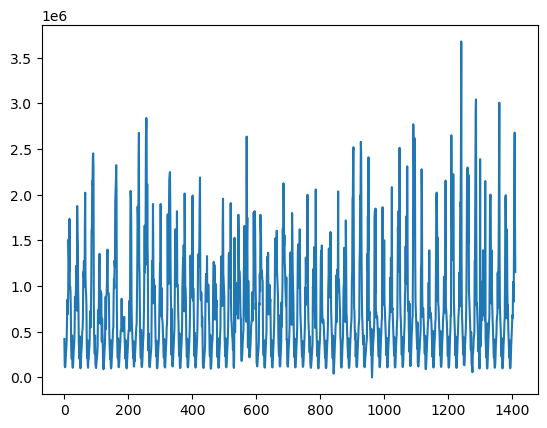

In [ ]:
aggregated_df.get("leaf_3")["#Events"].plot()

In [ ]:
phono = transform_category_to_list(available_categories, "Event Type")
aggregated_df = create_final_hierarchy(df_train, phono)

auc_hierarchy = calculate_AUC_hierarchy(aggregated_df)
print(round(auc_hierarchy, 4))

0.6688


In [ ]:
import pandas as pd
from tqdm import tqdm
import numpy as np
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import MinMaxScaler
import stumpy

# Função para adicionar resultados ao DataFrame
def add_result(df, dataset_name, hierarchy_name, auc_value):
    df.loc[len(df)] = [dataset_name, hierarchy_name, auc_value]
    return df

# Função para calcular AUC para um DataFrame específico
def calculate_auc_for_dataset(df, dataset_name, available_categories, categories, results_df):
    # Processar o fenótipo (pheno)
    if dataset_name == "Test":
        is_train = False
    else: 
        is_train = True
    try:
        pheno = pheno_to_dict(hierarchy)
        aggregated_df = create_final_hierarchy(df, pheno, is_train=is_train)
        auc_hierarchy = calculate_AUC_hierarchy(aggregated_df)
        results_df = add_result(results_df, dataset_name, "Pheno Hierarchy", round(auc_hierarchy, 4))
    except Exception as e:
        print(f"Erro ao processar fenótipo: {e}")
    
    # Processar o caso totalmente agregado (phono_agg)
    # try:
    #     phono_agg = [{}]
    #     aggregated_df = create_final_hierarchy(df, phono_agg, is_train=is_train)
    #     auc_hierarchy = calculate_AUC_hierarchy(aggregated_df)
    #     results_df = add_result(results_df, dataset_name, "Fully Aggregated Hierarchy", round(auc_hierarchy, 4))
    # except Exception as e:
    #     print(f"Erro ao processar caso totalmente agregado: {e}")
    
    # Processar as categorias
    # for category in categories:
    #     try:
    #         phono = transform_category_to_list(available_categories, category)
    #         aggregated_df = create_final_hierarchy(df, phono, is_train=is_train)
    #         auc_hierarchy = calculate_AUC_hierarchy(aggregated_df)
    #         results_df = add_result(results_df, dataset_name, f"Category: {category}", round(auc_hierarchy, 4))
    #     except Exception as e:
    #         print(f"Erro ao processar categoria {category}: {e}")
    

    # try:
    #     aux = build_hierarchy(filters)
    #     desaggregated_df = create_final_hierarchy(df, aux, is_train=is_train)
    #     auc_hierarchy = calculate_AUC_hierarchy(desaggregated_df)
    #     results_df = add_result(results_df, dataset_name, "Fully Desaggregated Hierarchy", round(auc_hierarchy, 4))
    # except Exception as e:
    #     print(f"Erro ao processar hierarquia desagregada: {e}")
    
    return results_df

# Criar um DataFrame vazio para armazenar os resultados
results = pd.DataFrame(columns=["Dataset", "Hierarchy", "AUC"])

# Lista de categorias para processar
categories = [
#     "Call Type",
#     "Event Type",
#     "Subscriber Type",
#     "Traffic Type",
#     "Service Type",
#     "Partner Description"
]

# Processar df_train
results = calculate_auc_for_dataset(df_train, "Train", available_categories, categories, results)

# Processar df_test
results = calculate_auc_for_dataset(df_test, "Test", available_categories, categories, results)

# Exibir a tabela de resultados
print(results)

# Salvar o DataFrame em um arquivo CSV (opcional)
results.to_csv("results_50G_10P.csv", index=False)

  Dataset        Hierarchy     AUC
0   Train  Pheno Hierarchy  0.7617
1    Test  Pheno Hierarchy  0.6783


In [ ]:
# Para o conjunto de treino (df_train)
train_counts = df_train.Anomaly.value_counts()
train_ratio = train_counts / len(df_train) * 100  # Converter para percentagem
print("Conjunto de Treino (df_train):")
print(f"Número de anomalias (1): {train_counts[1]}")
print(f"Número de casos normais (0): {train_counts[0]}")
print(f"Proporção de anomalias: {train_ratio[1]:.6f}%")
print(f"Proporção de casos normais: {train_ratio[0]:.6f}%")
print()

# Para o conjunto de teste (df_test)
test_counts = df_test.Anomaly.value_counts()
test_ratio = test_counts / len(df_test) * 100  # Converter para percentagem
print("Conjunto de Teste (df_test):")
print(f"Número de anomalias (1): {test_counts[1]}")
print(f"Número de casos normais (0): {test_counts[0]}")
print(f"Proporção de anomalias: {test_ratio[1]:.6f}%")
print(f"Proporção de casos normais: {test_ratio[0]:.6f}%")

Conjunto de Treino (df_train):
Número de anomalias (1): 3508
Número de casos normais (0): 627353
Proporção de anomalias: 0.556065%
Proporção de casos normais: 99.443935%

Conjunto de Teste (df_test):
Número de anomalias (1): 917
Número de casos normais (0): 326700
Proporção de anomalias: 0.279900%
Proporção de casos normais: 99.720100%
